# DỰ ÁN: PHÂN TÍCH CHẤT LƯỢNG KHÔNG KHÍ HÀ NỘI

# Phần 3: Phân tích chuỗi thời gian PM2.5 với mô hình ARIMA
Tác giả: Nam Aaron Nguyen
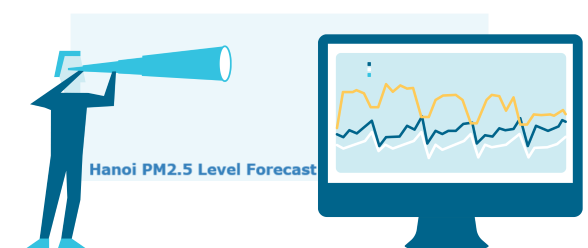

# I. Import thư viện

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import datetime
import seaborn as sns
import plotly.express as px
import inspect
import time
import warnings
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tools.sm_exceptions import ConvergenceWarning
warnings.simplefilter('ignore', ConvergenceWarning)
from sklearn.metrics import mean_absolute_error
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.ar_model import AutoReg
%matplotlib inline

# II. Đọc và xử lý dữ liệu

In [22]:
# Đọc file CSV vào DataFrame
df = pd.read_csv('Data/hanoi-aqi-weather-data.csv')  # Đường dẫn tới file CSV được tạo ở Part 1

# Chuyển cột 'Local Time' sang kiểu datetime
df['Local Time'] = pd.to_datetime(df['Local Time'])

# Đặt cột 'Local Time' làm index
df.set_index('Local Time', inplace=True)

# Hiển thị DataFrame
df  # Dùng df.head() để chỉ xem vài dòng đầu

,UTC Time,City,Country Code,Timezone,AQI,CO,NO2,O3,PM10,PM25,SO2,Clouds,Precipitation,Pressure,Relative Humidity,Temperature,UV Index,Wind Speed
Local Time,,,,,,,,,,,,,,,,,,
2023-03-08 00:00:00,2023-03-07T17:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,131,170.6,29.3,53.3,58.8,47.00,67.3,91,0.0,1016,86,21.2,0.0,2.00
2023-03-08 01:00:00,2023-03-07T18:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,126,158.7,25.0,54.0,56.3,45.00,65.0,100,0.0,1016,89,21.1,0.0,2.00
2023-03-08 02:00:00,2023-03-07T19:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,118,150.2,21.7,55.0,52.5,42.00,65.7,100,0.0,1016,90,20.9,0.0,1.66
2023-03-08 03:00:00,2023-03-07T20:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,126,141.6,18.3,56.0,56.3,45.00,66.3,100,0.0,1016,91,20.7,0.0,1.33
2023-03-08 04:00:00,2023-03-07T21:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,118,133.1,15.0,57.0,52.5,42.00,67.0,100,0.0,1015,92,20.5,0.0,1.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-03-07 20:00:00,2024-03-07T13:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,193,6738.4,36.7,21.4,139.3,87.86,12.0,100,0.0,1014,71,21.5,0.0,1.00
2024-03-07 21:00:00,2024-03-07T14:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,173,6693.2,29.3,19.5,140.6,73.00,6.0,100,0.0,1015,75,21.1,0.0,1.00
2024-03-07 22:00:00,2024-03-07T15:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,241,504.0,108.0,18.4,167.0,124.00,116.0,100,0.0,1016,80,20.6,0.0,1.00


## 2.1. Tạo chuỗi thời gian nồng độ PM2.5 theo ngày

In [23]:
df_pm25_hourly = df[['PM25']].copy()
df_pm25_daily = df_pm25_hourly.resample('D')['PM25'].agg('mean')
df_pm25 = df_pm25_daily
df_pm25


Local Time
2023-03-08     51.208333
2023-03-09     83.125000
2023-03-10     89.416667
2023-03-11     58.416667
2023-03-12     66.333333
                 ...    
2024-03-04     66.708333
2024-03-05    104.584583
2024-03-06     75.343333
2024-03-07     54.213750
2024-03-08     62.000000
Freq: D, Name: PM25, Length: 367, dtype: float64

## 2.2. Thông tin chuỗi thời gian

In [24]:
df_pm25.info()

<class 'pandas.Series'>
DatetimeIndex: 367 entries, 2023-03-08 to 2024-03-08
Freq: D
Series name: PM25
Non-Null Count  Dtype  
--------------  -----  
367 non-null    float64
dtypes: float64(1)
memory usage: 5.7 KB


Chuỗi gồm 367 giá trị nồng độ PM2.5 trung bình theo ngày, từ ngày 08/03/2023 đến ngày 08/03/2024.

# III. Khám phá dữ liệu

## 3.1. Kiểm tra tính dừng của dữ liệu (kiểm định Augmented Dickey-Fuller)

In [25]:
# Thực hiện kiểm định ADF (kiểm tra tính dừng)
adf_result = adfuller(df_pm25)
print('ADF Statistic:', adf_result[0])
print('p-value:', adf_result[1])
print('Critical Values:', adf_result[4])

ADF Statistic: -4.1120966137945585
p-value: 0.000924882046265438
Critical Values: {'1%': np.float64(-3.448544133483233), '5%': np.float64(-2.8695574079525565), '10%': np.float64(-2.5710411593052713)}


/tmp/ipykernel_45667/2480321151.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(df_pm25)


Theo kiểm định Augmented Dickey-Fuller (ADF), giá trị thống kê ADF nhỏ hơn tất cả các giá trị tới hạn và p-value nhỏ hơn mức ý nghĩa 1%. Do đó, ta bác bỏ giả thuyết không (H0) và kết luận rằng chuỗi có tính dừng.

## 3.2. Vẽ biểu đồ nồng độ PM2.5 theo ngày

<Axes: title={'center': 'Hanoi PM2.5 Levels, Daily Data'}, xlabel='Date', ylabel='PM2.5 Level'>

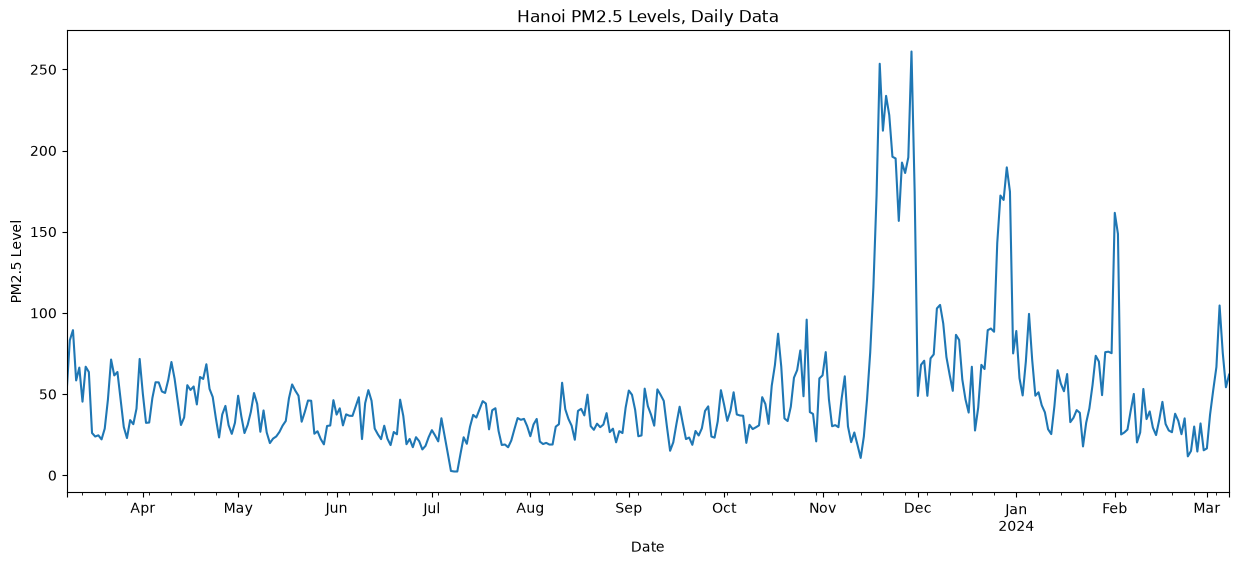

In [26]:
fig, ax = plt.subplots(figsize=(15, 6))
df_pm25.plot(xlabel = "Date",ylabel= "PM2.5 Level",
                           title= "Hanoi PM2.5 Levels, Daily Data", ax=ax)

Dữ liệu theo ngày có vẻ ít biến động hơn so với dữ liệu theo giờ ở notebook trước. Nguyên nhân là do việc gộp dữ liệu theo ngày giúp làm mượt các biến động trong chuỗi thời gian.

## 3.3. Vẽ biểu đồ ACF và PACF

Text(0.5, 1.0, 'Hanoi PM2.5 Readings, ACF')

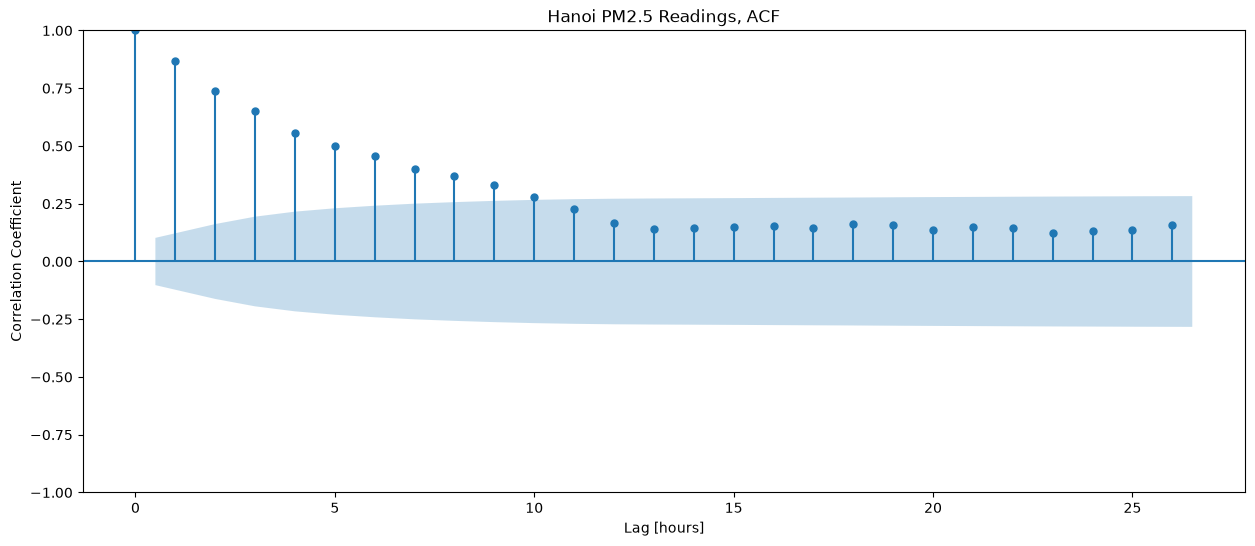

In [27]:
fig, ax = plt.subplots(figsize=(15, 6))
plot_acf(df_pm25, ax=ax)
plt.xlabel("Lag [hours]")
plt.ylabel("Correlation Coefficient")
plt.title("Hanoi PM2.5 Readings, ACF")


*Biểu đồ ACF thể hiện hệ số tương quan giữa chuỗi PM2.5 và các giá trị trễ (lag) của chính nó, cho thấy tự tương quan đáng kể ở nhiều độ trễ, đặc biệt là các độ trễ nhỏ. Vài độ trễ đầu tiên có tự tương quan dương cao, cho thấy giá trị hiện tại tương quan mạnh với các giá trị ngay trước đó. Hệ số tự tương quan giảm dần khi độ trễ tăng, cho thấy hiệu ứng "trí nhớ dài" – giá trị hiện tại chịu ảnh hưởng của giá trị nhiều ngày trước. Vùng tô màu xanh biểu thị khoảng tin cậy 95%, và nhiều độ trễ đầu nằm ngoài khoảng này, khẳng định tự tương quan là đáng kể. Việc không có các đỉnh lặp lại theo chu kỳ rõ ràng cho thấy không có tính mùa mạnh trong khoảng thời gian này.*

Text(0.5, 1.0, 'Hanoi PM2.5 Readings, PACF')

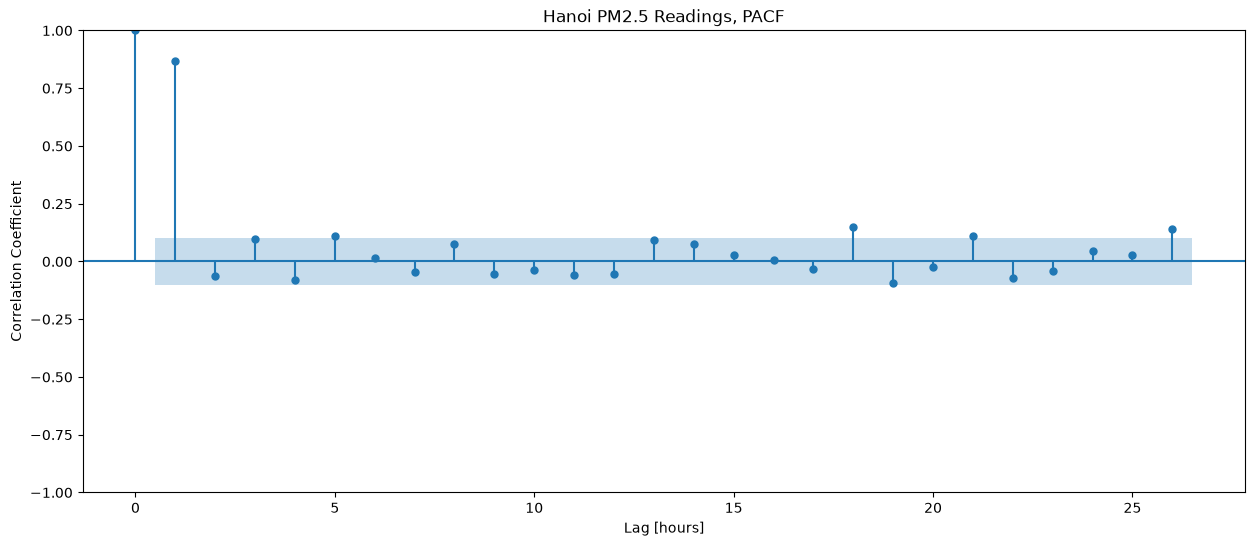

In [28]:
fig, ax = plt.subplots(figsize=(15, 6))
plot_pacf(df_pm25, ax=ax)
plt.xlabel("Lag [hours]")
plt.ylabel("Correlation Coefficient")
plt.title("Hanoi PM2.5 Readings, PACF")

*Biểu đồ PACF thể hiện hệ số tương quan riêng phần giữa chuỗi PM2.5 và các giá trị trễ của nó, sau khi đã loại bỏ ảnh hưởng tuyến tính của các độ trễ trung gian. Biểu đồ giảm mạnh sau độ trễ đầu tiên, với các đỉnh đáng kể ở độ trễ 1 và 2, cho thấy giá trị đo phụ thuộc vào giá trị của một và hai ngày trước đó. Sau độ trễ 2, các hệ số nằm trong khoảng tin cậy, cho thấy sự phụ thuộc không còn đáng kể sau khi đã tính tới hai độ trễ đầu. Điều này gợi ý một quá trình AR(2), trong đó giá trị hiện tại chủ yếu chịu ảnh hưởng của hai giá trị trước đó. Tuy nhiên, bậc chính xác có thể được tinh chỉnh dựa trên các bước chẩn đoán mô hình tiếp theo.*

# IV. Chia dữ liệu

## 4.1. Chia dữ liệu thành tập huấn luyện và tập kiểm tra

In [29]:
int(len(df_pm25)) *0.8

293.6

In [30]:
cutoff_test = int(len(df_pm25)* 0.8) 
df_pm25_train = df_pm25.iloc[:cutoff_test]
df_pm25_test = df_pm25.iloc[cutoff_test:]
print("df_pm25_train shape:", df_pm25_train.shape)
print("df_pm25_test shape:", df_pm25_test.shape)

df_pm25_train shape: (293,)
df_pm25_test shape: (74,)


Dữ liệu được chia thành 80% tập huấn luyện (train) và 20% tập kiểm tra (test).

## 4.2. Kiểm tra tính dừng trên tập huấn luyện

In [31]:
# Thực hiện kiểm định ADF (kiểm tra tính dừng)
adf_result = adfuller(df_pm25_train)
print('ADF Statistic:', adf_result[0])
print('p-value:', adf_result[1])
print('Critical Values:', adf_result[4])

ADF Statistic: -2.6121908805743956
p-value: 0.09050374592428329
Critical Values: {'1%': np.float64(-3.4540076534999957), '5%': np.float64(-2.8719557347997178), '10%': np.float64(-2.5723200648758366)}


/tmp/ipykernel_45667/55713627.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(df_pm25_train)


Có thể thấy p-value lớn hơn mức ý nghĩa 5%, nghĩa là không thể bác bỏ giả thuyết không (H0). Nói cách khác, dữ liệu huấn luyện không có tính dừng.

Mô hình ARIMA thường hiệu quả hơn khi áp dụng cho chuỗi thời gian có tính dừng. Vì vậy, kỹ thuật lấy sai phân (differencing) sẽ được sử dụng trong mô hình ARIMA.

# V. Xây dựng mô hình

## 5.1. Mô hình cơ sở (Baseline)

In [32]:
df_pm25_train_mean = df_pm25_train.mean()
df_pm25_pred_baseline = [df_pm25_train_mean]*len(df_pm25_train)
mae_baseline = mean_absolute_error(df_pm25_train, df_pm25_pred_baseline)

print("Mean P2 Reading:", round(df_pm25_train_mean, 2))
print("Baseline MAE:", round(mae_baseline, 2))

Mean P2 Reading: 47.64
Baseline MAE: 23.13


Tôi sử dụng sai số tuyệt đối trung bình (MAE) để đánh giá hiệu quả của các mô hình ARIMA. MAE được định nghĩa là trung bình của trị tuyệt đối chênh lệch giữa giá trị thực tế và giá trị dự đoán.

Vì vậy, tôi tính MAE của mô hình cơ sở (baseline) – mô hình trung bình, luôn dự đoán bằng giá trị trung bình của tập huấn luyện cho mọi thời điểm trong tương lai. Nếu MAE của mô hình đã huấn luyện nhỏ hơn baseline, mô hình đó hoạt động tốt hơn baseline, tức là nó nắm bắt được các quy luật và xu hướng trong dữ liệu mà baseline không làm được.

## 5.2. Thử nghiệm các mô hình

Ở phần này, tôi sẽ thử nghiệm mô hình ARIMA(p, d, q) với các bộ tham số khác nhau.
- p: Số quan sát trễ được đưa vào mô hình (bậc tự hồi quy – AR).

- d: Số lần lấy sai phân cần thiết để chuỗi đạt tính dừng.

- q: Số sai số dự báo trễ được đưa vào mô hình (bậc trung bình trượt – MA).

Vì tập huấn luyện không có tính dừng, tham số d được cố định bằng 1 trong mọi lần thử.

### 5.2.1. Khai báo danh sách tham số

In [33]:
p_params = range(0, 8, 1)
q_params = range(0, 3, 1)
list(p_params)

[0, 1, 2, 3, 4, 5, 6, 7]

### 5.2.2. Huấn luyện mô hình ARIMA với từng bộ tham số và tính MAE của mỗi mô hình

In [34]:
# Tạo dictionary để lưu các giá trị MAE
mae_grid = dict()
# Vòng lặp ngoài: duyệt qua các giá trị có thể của `p`
for p in p_params:
    # Tạo cặp key-value trong dict. Key là `p`, value là danh sách rỗng.
    mae_grid[p] = list()
    # Vòng lặp trong: duyệt qua các giá trị có thể của `q`
    for q in q_params:
        # Tổ hợp siêu tham số cho mô hình
        order = (p, 1, q)
        # Ghi lại thời điểm bắt đầu
        start_time = time.time()
        # Huấn luyện mô hình
        model = ARIMA(df_pm25_train, order=order).fit()
        # Tính thời gian huấn luyện mô hình
        elapsed_time = round(time.time() - start_time, 2)
        print(f"Trained ARIMA {order} in {elapsed_time} seconds.")
        # Dự đoán trên chính tập huấn luyện (in-sample)
        df_pm25_pred = model.predict()
        # Tính MAE trên tập huấn luyện
        mae = mean_absolute_error(df_pm25_train, df_pm25_pred)
        # Thêm MAE vào danh sách tương ứng trong dictionary
        mae_grid[p].append(mae)

print()
print(mae_grid)


Trained ARIMA (0, 1, 0) in 0.02 seconds.
Trained ARIMA (0, 1, 1) in 0.03 seconds.
Trained ARIMA (0, 1, 2) in 0.06 seconds.
Trained ARIMA (1, 1, 0) in 0.03 seconds.
Trained ARIMA (1, 1, 1) in 0.11 seconds.
Trained ARIMA (1, 1, 2) in 0.14 seconds.
Trained ARIMA (2, 1, 0) in 0.06 seconds.
Trained ARIMA (2, 1, 1) in 0.16 seconds.


/home/hoang/Big_Data/BDT/lib/python3.13/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


Trained ARIMA (2, 1, 2) in 0.28 seconds.
Trained ARIMA (3, 1, 0) in 0.07 seconds.
Trained ARIMA (3, 1, 1) in 0.26 seconds.
Trained ARIMA (3, 1, 2) in 0.38 seconds.
Trained ARIMA (4, 1, 0) in 0.16 seconds.
Trained ARIMA (4, 1, 1) in 0.46 seconds.
Trained ARIMA (4, 1, 2) in 0.52 seconds.
Trained ARIMA (5, 1, 0) in 0.21 seconds.
Trained ARIMA (5, 1, 1) in 0.47 seconds.
Trained ARIMA (5, 1, 2) in 0.86 seconds.
Trained ARIMA (6, 1, 0) in 0.14 seconds.
Trained ARIMA (6, 1, 1) in 0.31 seconds.
Trained ARIMA (6, 1, 2) in 0.99 seconds.
Trained ARIMA (7, 1, 0) in 0.16 seconds.
Trained ARIMA (7, 1, 1) in 0.35 seconds.
Trained ARIMA (7, 1, 2) in 1.1 seconds.

{0: [12.10383674630261, 12.099917051285475, 12.019601593773187], 1: [12.100772229117345, 11.716650621305082, 11.724709844721016], 2: [12.056589327266996, 11.725425226725317, 11.69888877431417], 3: [12.022314745295175, 11.714131033637566, 11.699040386995934], 4: [11.884050129422166, 11.71623649897057, 11.691362951349154], 5: [11.83492244137454

### 5.2.3. Tạo bảng MAE của các mô hình để tìm mô hình tốt nhất

In [35]:
mae_df = pd.DataFrame(mae_grid)
mae_df.round(4)

,0,1,2,3,4,5,6,7
0,12.1038,12.1008,12.0566,12.0223,11.8841,11.8349,11.8152,11.7666
1,12.0999,11.7167,11.7254,11.7141,11.7162,11.6377,11.7871,11.7893
2,12.0196,11.7247,11.6989,11.6990,11.6914,11.6504,11.6550,11.7520


Theo bảng trên, mô hình ARIMA(5,1,1) có MAE thấp nhất. Vì vậy, ta chọn mô hình này để phân tích tiếp.

### 5.2.4. Chẩn đoán phần dư

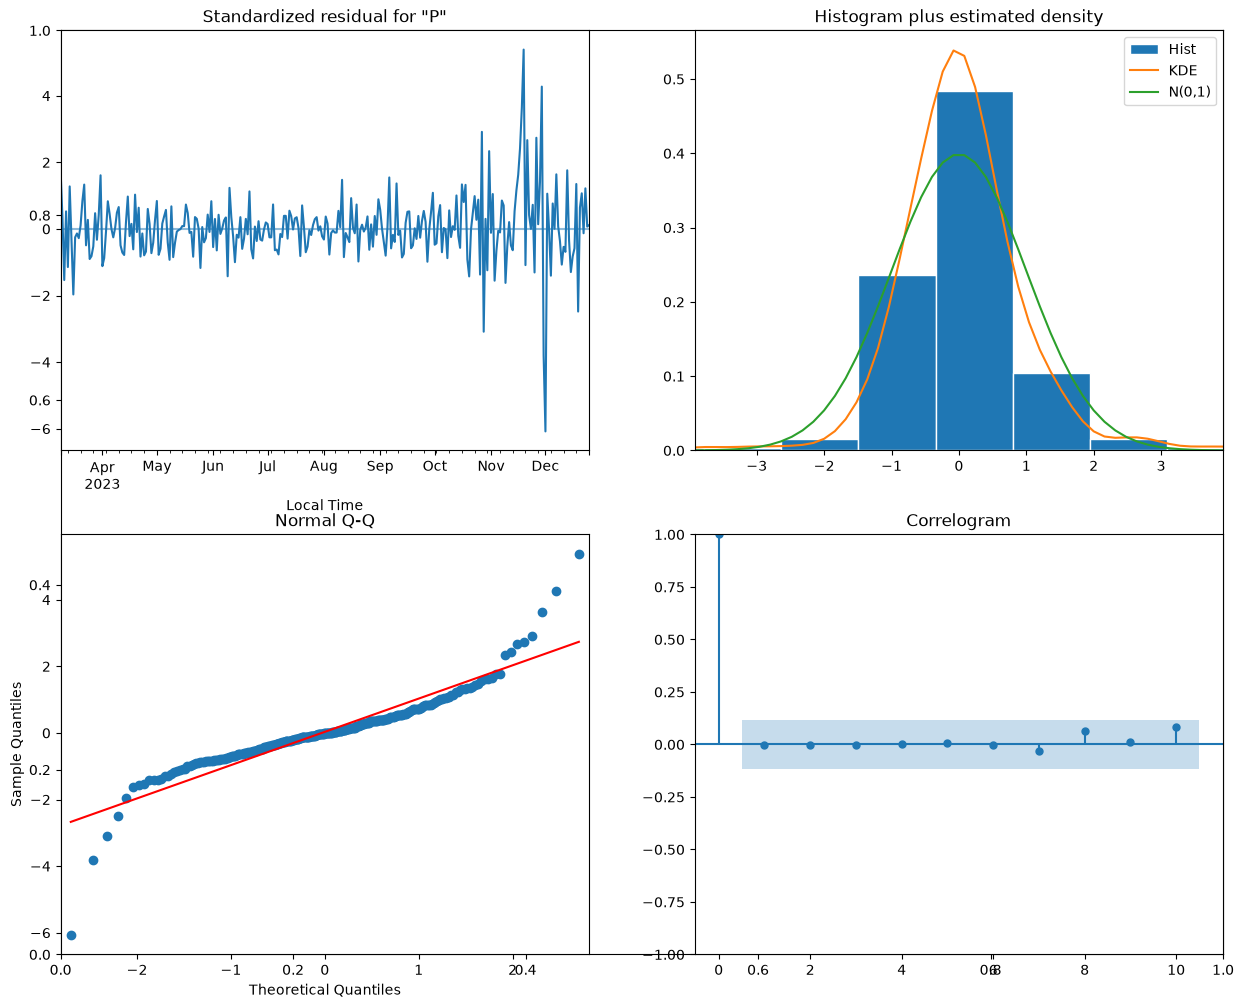

In [36]:
model = ARIMA(df_pm25_train, order=(5,1,1))
results = model.fit()
fig, ax = plt.subplots(figsize=(15, 12))
results.plot_diagnostics(fig=fig)
# Lưu biểu đồ thành file ảnh (vd: PNG)
plt.savefig('example_plot.png')

Chẩn đoán phần dư (residual diagnostics) trong phân tích chuỗi thời gian rất quan trọng để đánh giá mức độ phù hợp và hiệu quả của mô hình. Các bước chẩn đoán này giúp phát hiện những quy luật hoặc cấu trúc còn sót lại trong phần dư mà mô hình chưa nắm bắt được, từ đó cho biết các giả định của mô hình có được thỏa mãn hay không.

**1. Biểu đồ phần dư chuẩn hóa (Standardized Residuals)**
- Phần dư phân bố khá ngẫu nhiên quanh 0 trong phần lớn thời gian. Các đỉnh lớn vào tháng 11 và tháng 12 cho thấy có các giá trị ngoại lai trong khoảng thời gian đó.

**2. Histogram và đường mật độ ước lượng (Histogram plus Estimated Density)**
- Phần dư có vẻ tuân theo phân phối chuẩn (hình chuông) với tâm ở 0.

**3. Biểu đồ Normal Q-Q (Quantile-Quantile)**
- Các điểm nằm xấp xỉ trên đường 45 độ, có một số giá trị ngoại lai ở hai đầu.

**4. Biểu đồ tương quan (Correlogram)**
- Không có tự tương quan đáng kể, các hệ số tự tương quan sau độ trễ 0 đều nằm trong khoảng tin cậy – đây là kết quả lý tưởng.

Dựa trên kết quả chẩn đoán phần dư, có thể nói mô hình là đáng tin cậy.

## 5.3. Đánh giá mô hình

### 5.3.1. Kiểm định Walk-forward (Walk-forward Validation)

Walk-forward validation là kỹ thuật phổ biến trong dự báo chuỗi thời gian, bao gồm cả mô hình ARIMA. Quy trình gồm: lần lượt huấn luyện mô hình trên dữ liệu lịch sử tới một thời điểm nhất định, dự đoán cho bước thời gian tiếp theo, sau đó cập nhật mô hình bằng giá trị quan sát thực tế của bước thời gian đó.

In [37]:
df_pm25_pred_wfv = pd.Series()  # Khởi tạo một Series rỗng thay vì list
history = df_pm25_train.copy()
for i in range(len(df_pm25_test)):
    model = ARIMA(history, order = (5, 1, 1)).fit()
    next_pred = model.forecast()
    df_pm25_pred_wfv = pd.concat([df_pm25_pred_wfv, pd.Series(next_pred)])
    # Làm tròn toàn bộ Series tới 2 chữ số thập phân
    df_pm25_pred_wfv = df_pm25_pred_wfv.round(2)
    history = pd.concat([history, df_pm25_test[next_pred.index]])


In [38]:
df_pm25_pred_wfv

2023-12-26     87.47
2023-12-27    138.09
2023-12-28    162.17
2023-12-29    160.73
2023-12-30    179.05
               ...  
2024-03-04     53.29
2024-03-05     66.08
2024-03-06     97.23
2024-03-07     66.75
2024-03-08     56.57
Length: 74, dtype: object

### 5.3.2. MAE của Walk-forward Validation

In [39]:
test_mae = mean_absolute_error(df_pm25_test, df_pm25_pred_wfv)
print("Test MAE (walk forward validation):", round(test_mae, 2))

Test MAE (walk forward validation): 16.95


MAE trên tập kiểm tra là 16.95, thấp hơn MAE của baseline là 23.13. Điều này cho thấy mô hình hoạt động tốt và có thể coi là chấp nhận được và đáng tin cậy.

# VI. Trình bày kết quả

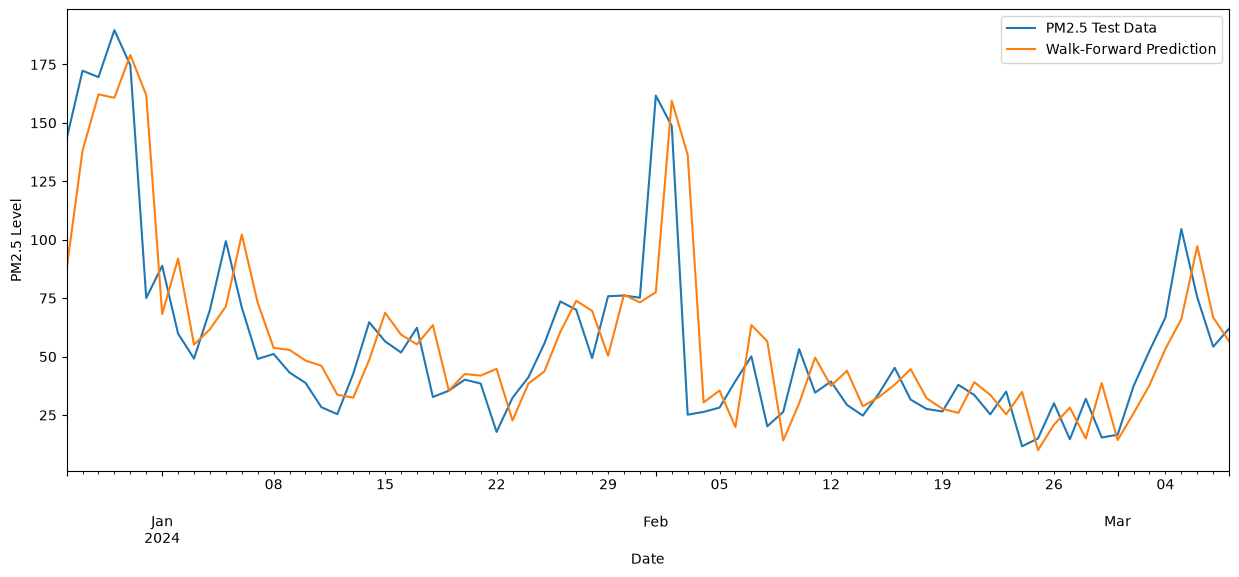

In [40]:
ax = df_pm25_test.plot(label = 'PM2.5 Test Data', figsize=(15, 6))
df_pm25_pred_wfv.plot(ax=ax, label='Walk-Forward Prediction')
plt.ylabel('PM2.5 Level')
plt.xlabel('Date')
plt.legend()
plt.show()

Biểu đồ trên so sánh dữ liệu PM2.5 của tập kiểm tra với kết quả dự đoán Walk-Forward. Đường màu xanh dương biểu thị nồng độ PM2.5 thực tế trong tập kiểm tra, còn đường màu cam biểu thị giá trị dự đoán của mô hình ARIMA bằng phương pháp walk-forward validation.

Từ biểu đồ có thể thấy dự đoán của mô hình bám sát xu hướng của dữ liệu thực tế, nắm bắt được các đỉnh và đáy quan trọng. Điều này cho thấy mô hình dự báo nồng độ PM2.5 tốt, cho kết quả ổn định và đáng tin cậy. Việc hai đường gần như trùng khớp cho thấy mô hình nắm bắt hiệu quả các quy luật tiềm ẩn trong dữ liệu chuỗi thời gian.